# TASK 4: Visualizing Fire Scars Through False Color

**Github Repository Link:** 
https://github.com/Amapolaa/eds220-hw4.git

- **Author:** Amapola Garcia
- **Date:** November 15,2026
- **Class Title:** EDS 220

---

## About
In February 2021, a severe winter storm swept across the U.S. central plains, setting national records for low temperatures. Texas was especially affected, with widespread electricity and water outages. This event ranks among the most severe winter weather incidents in history, resulting in loss of life and long-term economic consequences. In the aftermath, political debate and blame can obscure the facts.
### Purpose: 
This notebook uses Landsat 8 satellite imagery and fire perimeter data to generate true-color and false-color images of the Eaton and Palisades fires. It also overlays fire perimeters on the false-color image.
### Highlights:
- Explored the fire perimeter datasets,including their attributes,geometry types, and CRS.
- Explored the Landsat dataset and restored its CRS information.
- Created true color and false color images from Landsat bands,checking and/or replacing missing values.
- Mapped the false color image with outlines of the Eaton and Palisades fire perimeters.
### Readings

- NASA EARTH OBSERVATORY
- WHAT ARE THE BANDS DESIGNATION
- COmmon LANDSAT BAND COMBOS

### About the Data
In this task you will see two datasets:

**First dataset:Landsat Collection 2 Level-2 atmospherically:**
Collection of bands (**red,green,blue,near-infrared and shortwave infared**)
  - `landsat8-2025-02-23-palisades-eaton.nc`
  
**Second dataset:Fire perimeters for the Eaton and Palisades fires:** 
*More than one File*
  - `Eaton_Perimeter_20250121`
  - `Palisades_Perimieter_20250121`

### References
---
Los Angeles County Enterprise GIS. (2025). *Palisades and Eaton dissolved fire perimeters (2025)* [GIS data]. https://egis-lacounty.hub.arcgis.com/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about

Microsoft Planetary Computer. (n.d.). *Landsat Collection 2 Level-2* [Data catalog]. https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2

M. M. Bennett, J. K. Chen, L. F. Alvarez León, and C. J. Gleason, “The politics of pixels: A review and agenda for critical remote sensing,” Progress in Human Geography, vol. 46, no. 3, pp. 729–752, June 2022, doi: 10.1177/03091325221074691. Available: https://journals.sagepub.com/doi/10.1177/03091325221074691. [Accessed: Nov. 14, 2024]

MEDS/EDS 220. (n.d.). *Assignment 4: Visualizing fire scars through false color*. https://meds-eds-220.github.io/MEDS-eds-220-course/assignments/assignment4-palisades-eaton-fires.html

## COMPLETE WORKFLOW
---
Complete workflow of our work.

sh: 1: getfattr: not found


Index(['OBJECTID', 'YEAR_', 'STATE', 'AGENCY', 'UNIT_ID', 'FIRE_NAME', 'type',
       'INC_NUM', 'IRWINID', 'ALARM_DATE', 'CONT_DATE', 'CAUSE', 'C_METHOD',
       'OBJECTIVE', 'GIS_ACRES', 'COMMENTS', 'COMPLEX_NA', 'COMPLEX_ID',
       'FIRE_NUM', 'GlobalID', 'DECADES', 'Shape__Are', 'Shape__Len',
       'geometry'],
      dtype='object')
(1, 24)
EPSG:4269
Index(['OBJECTID', 'YEAR_', 'STATE', 'AGENCY', 'UNIT_ID', 'FIRE_NAME', 'type',
       'INC_NUM', 'IRWINID', 'ALARM_DATE', 'CONT_DATE', 'CAUSE', 'C_METHOD',
       'OBJECTIVE', 'GIS_ACRES', 'COMMENTS', 'COMPLEX_NA', 'COMPLEX_ID',
       'FIRE_NUM', 'GlobalID', 'DECADES', 'Shape__Are', 'Shape__Len',
       'geometry'],
      dtype='object')
(1, 24)
EPSG:4269


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


red False
green True
blue True


/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


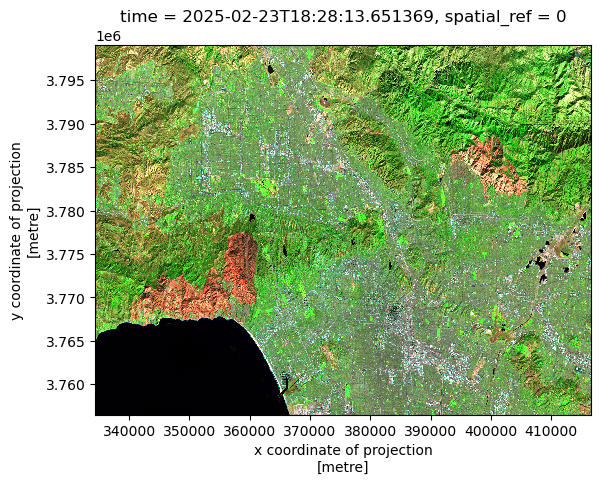

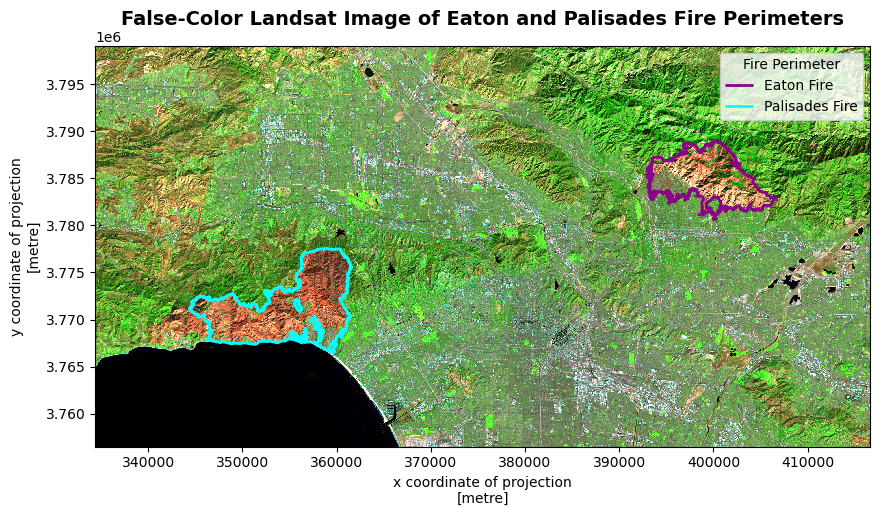

In [133]:
###COMPLETE WORKFLOW####
#(1)
#import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rioxarray as rioxr #required to register the rasterio engine
from shapely import box
#allows you to use xr
import xarray as xr

#(1b)
#Import Eaton perimeter data
edf = os.path.join('data/Eaton_Perimeter_20250121/Eaton_Perimeter_20250121.shp')
eaton = gpd.read_file(edf)

#Import Palisadas perimeter data
pdf = os.path.join("data", "Palisades_Perimieter_20250121", "Palisades_Perimieter_20250121.shp")
palisades = gpd.read_file(pdf)

#Import Net CDF
#use xr.open_dataset()
netcdf = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')

#(2)
#exploration the eaton perimeter using: head(),columns,shape,value_counts and crs
print(eaton.columns)
print(eaton.shape)
#check geometry type
eaton.geom_type.value_counts()
#check crs
print(eaton.crs)

#exploration the palisades perimeter using: head(),columns,shape,value_counts and crs
print(palisades.columns)
print(palisades.shape)
#check geometry type
palisades.geom_type.value_counts()
#check crs
print(palisades.crs)

#(3)
#had to add dataset for 5a to work :(
#netcdf = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')

#print spatial_ref to check attributes
crs_wkt = netcdf.spatial_ref.attrs["crs_wkt"]

#recover the geospatial info using rio.write_crs() & spatial reference
netcdf = netcdf.rio.write_crs(crs_wkt)

#(4)
#(5a)select the red, green, and blue variables (in that order)holding the Landsat data
netcdf[["red","green", "blue"]].to_dataarray().plot.imshow(rgb="variable")

#(4b)resolve the other warning, identify which bands have nan values. 
bands = netcdf[["red","green", "blue"]]

for band in bands:
    print(band,np.isnan(netcdf[band]).any().item())
    
#replace any nan values in the landsat data with zero
netcdf = netcdf.fillna(0)

#(4c)Create a new true color image that gets plotted without warnings.
netcdf[["red","green", "blue"]].to_dataarray().plot.imshow(rgb="variable",robust=True)

#(5)
#create a false color image by plotting:
#the shortwave infrared(swir22),near-infrared,and red (in that order)
false_image = netcdf[['swir22',"nir08","red"]].to_dataarray().plot.imshow(
    rgb="variable",robust=True)

#(6)
#create a false color image by plotting:
eaton_projected = eaton.to_crs(netcdf.rio.crs)
palisades_projected = palisades.to_crs(netcdf.rio.crs) 

#Plot
#(swir22) appears as red,(nir08) as green,and (red) as blue
fig, ax=plt.subplots(figsize=(10,8))
netcdf[['swir22',"nir08","red"]].to_dataarray().plot.imshow(
    rgb="variable",
    robust=True,
    ax=ax
)
#overlays each fire perimeters as colored outlines
eaton_projected.boundary.plot(
    ax=ax,
    color='darkmagenta',
    linewidth=2,
    label="Eaton Fire"
)
palisades_projected.boundary.plot(
    ax=ax,
    color='aqua',
    linewidth=2,
    label="Palisades Fire"
)
#adding the map title and a legend
ax.set_title("False-Color Landsat Image of Eaton and Palisades Fire Perimeters",
            fontsize=14, weight='bold', pad=15)
ax.legend(title="Fire Perimeter")


plt.show()

---
## 1. Import Libraries

In [134]:
#import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

import rioxarray as rioxr #required to register the rasterio engine
from shapely import box

#allows you to use xr
import xarray as xr

## 1b. Import the data
---
- Import the dire perimeter data
- Import the Landsat data using `xr.open_dataset()`.


In [135]:
#Import Eaton perimeter data
edf = os.path.join('data/Eaton_Perimeter_20250121/Eaton_Perimeter_20250121.shp')
eaton = gpd.read_file(edf)

In [136]:
#Import Palisadas perimeter data
pdf = os.path.join("data", "Palisades_Perimieter_20250121", "Palisades_Perimieter_20250121.shp")
palisades = gpd.read_file(pdf)

In [137]:
#Import Net CDF
#use xr.open_dataset()
netcdf = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')
#netcdf

sh: 1: getfattr: not found


## 2. Fire perimeter data exploration
---
Explore the fire perimeter data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include, at least, the CRS of the data and whether this is projected or geographic.



In [138]:
#checking the dataset
eaton.head() #one row & 24 cols

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},2025-01-08T00:00:00Z,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((-118.10093 34.16680, -118.1008..."


In [139]:
#checking the dataset
palisades.head() #one row & 24 cols

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07T00:00:00Z,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((-118.51974 34.02996, -118.5198..."


In [140]:
#exploration the eaton perimeter using: head(),columns,shape,value_counts and crs (week6)
print(eaton.columns)
print(eaton.shape)
#check geometry types
eaton.geom_type.value_counts()
#check crs
print(eaton.crs)

Index(['OBJECTID', 'YEAR_', 'STATE', 'AGENCY', 'UNIT_ID', 'FIRE_NAME', 'type',
       'INC_NUM', 'IRWINID', 'ALARM_DATE', 'CONT_DATE', 'CAUSE', 'C_METHOD',
       'OBJECTIVE', 'GIS_ACRES', 'COMMENTS', 'COMPLEX_NA', 'COMPLEX_ID',
       'FIRE_NUM', 'GlobalID', 'DECADES', 'Shape__Are', 'Shape__Len',
       'geometry'],
      dtype='object')
(1, 24)
EPSG:4269


In [141]:
#exploration the palisades perimeter using: head(),columns,shape,value_counts and crs
print(palisades.columns)
print(palisades.shape)
#check geometry types
palisades.geom_type.value_counts()
#check crs
print(palisades.crs)

Index(['OBJECTID', 'YEAR_', 'STATE', 'AGENCY', 'UNIT_ID', 'FIRE_NAME', 'type',
       'INC_NUM', 'IRWINID', 'ALARM_DATE', 'CONT_DATE', 'CAUSE', 'C_METHOD',
       'OBJECTIVE', 'GIS_ACRES', 'COMMENTS', 'COMPLEX_NA', 'COMPLEX_ID',
       'FIRE_NUM', 'GlobalID', 'DECADES', 'Shape__Are', 'Shape__Len',
       'geometry'],
      dtype='object')
(1, 24)
EPSG:4269


### 2b. Summary
---

I examined the Eaton and Palisades fire perimeter layers above. Each layer contains one feature and 24 columns,including fire name, year, acreage, and geometry. Both layers use `EPSG:4269(NAD83)` a **geographic coordinate reference system(CRS)**. So coordinates are expressed in degrees. Because the layers share columns and CRS, they can be combined for mapping while maintaining each fire as a separate feature.

## 3. NetCDF data import and exploration
---
a. Explore the data and write a brief summary of the information you obtained from the preliminary exploration.

b. Your summary should include a description of the data’s variables, dimensions, and coordinates.

In [142]:
#(a)- Exploration looking at the datasets: dimensions,coordinates, and variables(week7)
#In this raster, y is the vertical direction and x is the horizontal direction
netcdf 

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

### 3b. Summary
---
The Landsat dataset contains five image bands:`(red,green,blue,near-infrared(nir08),and shortwave infrared(swir22)`. Each band is represented as two-dimensional array with **(y(rows):1418, x(cols):2742)**. The dataset includes x and y coordinates for the grid and a single time coordinateAdditionally, a `spatial_ref` variable provides spatial reference information.

## 4. Restoring geospatial information
---
a.Use rio.crs to print the CRS of this dataset. Is this a geospatial object?

b.You may have noticed in section 3 that the geospatial information for this dataset is stored in the variable `spatial_ref`. Print the CRS by accessing the `spatial_ref.crs_wkt` attribute of the dataset.

c. Recover the geospatial information by using rio.write_crs() and the spatial reference information from part b.

d.Print the CRS of the updated dataset.

In [143]:
#A.Using rio.crs to print crs 
print(netcdf.rio.crs) #prints none


None


In [144]:
#B.print spatial_ref to check attributes
print(netcdf.spatial_ref)

<xarray.DataArray 'spatial_ref' ()> Size: 8B
[1 values with dtype=int64]
Coordinates:
    time     datetime64[ns] 8B ...
Attributes: (12/18)
    crs_wkt:                           PROJCS["WGS 84 / UTM zone 11N",GEOGCS[...
    semi_major_axis:                   6378137.0
    semi_minor_axis:                   6356752.314245179
    inverse_flattening:                298.257223563
    reference_ellipsoid_name:          WGS 84
    longitude_of_prime_meridian:       0.0
    ...                                ...
    longitude_of_central_meridian:     -117.0
    false_easting:                     500000.0
    false_northing:                    0.0
    scale_factor_at_central_meridian:  0.9996
    spatial_ref:                       PROJCS["WGS 84 / UTM zone 11N",GEOGCS[...
    GeoTransform:                      334395.0 30.0 0.0 3799065.0 0.0 -30.0


In [145]:
#had to add dataset for 5a to work :(
netcdf = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')

#1B.get the crs info stored in spatial_ref
crs_wkt = netcdf.spatial_ref.attrs["crs_wkt"]

print(crs_wkt)

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


sh: 1: getfattr: not found


In [146]:
#C.recover the geospatial info using rio.write_crs() & spatial reference
netcdf = netcdf.rio.write_crs(crs_wkt)

#D.check to see if its been restored
#should print the EPSG
print(netcdf.rio.crs) #EPSG:32611

EPSG:32611


- After restoring the geospatial information, the landsat dataset CRS is now`EPSG:32611` with projected coordinate systems in meters.

- **Note** that the fire perimeters layes have a different CRS`EPSG:4269`that uses geographic coordinates in degree

## 5. True color image
---
a. Without creating any new variables:
- select the red, green, and blue variables (in that order) of the `xarray.Dataset` holding the Landsat data(netcdf)
- convert it to an `xarray.DataArray` using the `to_dataarray()` method, and then
- use `.plot.imshow()` to create an RGB image with the data. There will be a warning; that’s ok.

b. Adjust the scale used for plotting the bands to get a true color image. HINT: Check the robust parameter.
To resolve the other warning, identify which bands have nan values. HINT: There are many ways of doing so. One option is to use numpy.isnan().

c. Use the .fillna() method for xarray.Datasets to replace any nan values in the Landsat data with zero.

d. Create a new true color image that gets plotted without warnings.

e. In a markdown cell write a brief explanation comparing the outputs for parts (a) and (e).

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


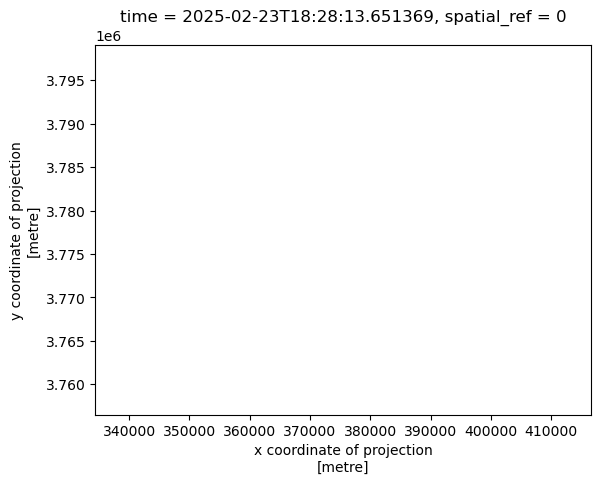

In [147]:
#A.select red,green, and blue variables(in that order)
#convert using to_dataarray() method & use .plot.imshow()to create RGB image
netcdf[["red","green", "blue"]].to_dataarray().plot.imshow(rgb="variable")

/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


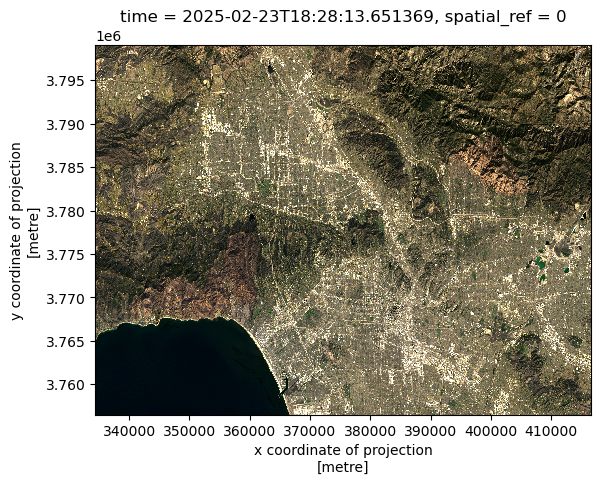

In [148]:
#B.adjust the scale for plotting bands (robust =False)
#robust must be True to set the display range, to improve the contrast
netcdf[["red","green", "blue"]].to_dataarray().plot.imshow(rgb="variable",robust=True)

In [149]:
#c.resolve the warning and identify which bands have nan value
# use numpy.isnan()
#going to use in class example
bands = netcdf[["red","green", "blue"]]

for band in bands:
    print(band,np.isnan(netcdf[band]).any().item())

red False
green True
blue True


In [150]:
#D.Use .fillna() method for green and blue
netcdf = netcdf.fillna(0)

netcdf

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          (y, x) float32 16MB 1.024e+04 9.886e+03 ... 1.019e+04 9.967e+03
    green        (y, x) float32 16MB 9.93e+03 9.687e+03 ... 9.984e+03 9.662e+03
    blue         (y, x) float32 16MB 9.29e+03 9.183e+03 ... 9.49e+03 9.187e+03
    nir08        (y, x) float32 16MB 1.331e+04 1.313e+04 ... 1.287e+04 1.306e+04
    swir22       (y, x) float32 16MB 1.43e+04 1.437e+04 ... 1.406e+04 1.329e+04

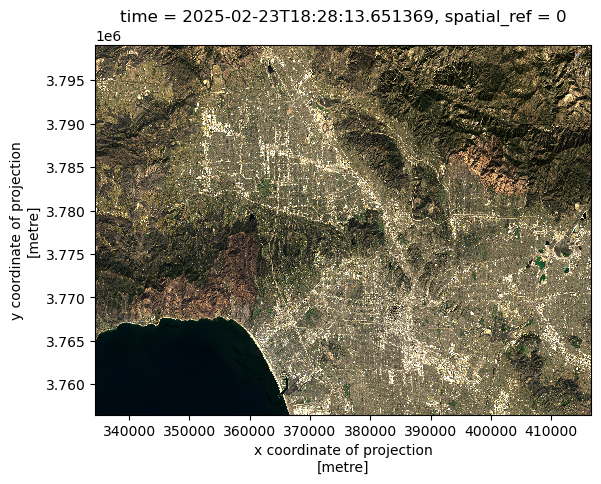

In [151]:
#E. create a new true color image that gets plotted without warning
netcdf[["red","green", "blue"]].to_dataarray().plot.imshow(rgb="variable",robust=True)
#no more warning 

## 6. False color image
Without creating any new variables, create a false color image by plotting the shortwave infrared (swir22), near-infrared, and red variables (in that order).

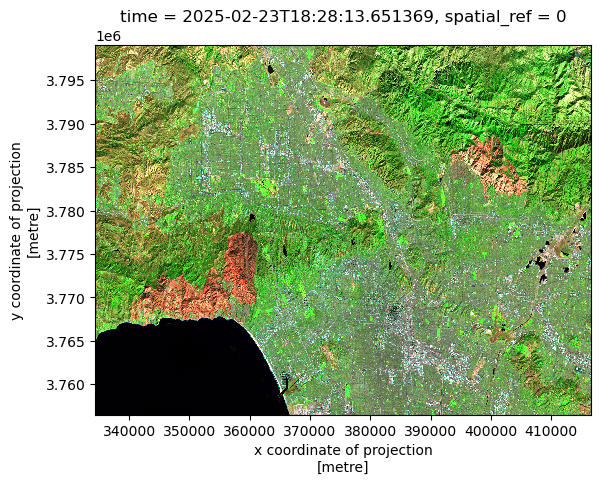

In [152]:
#create a false color image by plotting:
#the shortwave infrared(swir22),near-infrared,and red (in that order)
false_image = netcdf[['swir22',"nir08","red"]].to_dataarray().plot.imshow(
    rgb="variable",robust=True)

## 7. Map
---
a. Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire perimeters. Customize it appropriately including, at least, an informative title and legend. You may also want to include text on the map to identify which fire is which.

b. Write a figure description for the map including a brief explanation of how false color imagery is being used.

In [153]:
#A1.Create a map showing:
# print crs fire perimeters layers: eaton & palisades
eaton_projected = eaton.to_crs(netcdf.rio.crs)
palisades_projected = palisades.to_crs(netcdf.rio.crs)                          

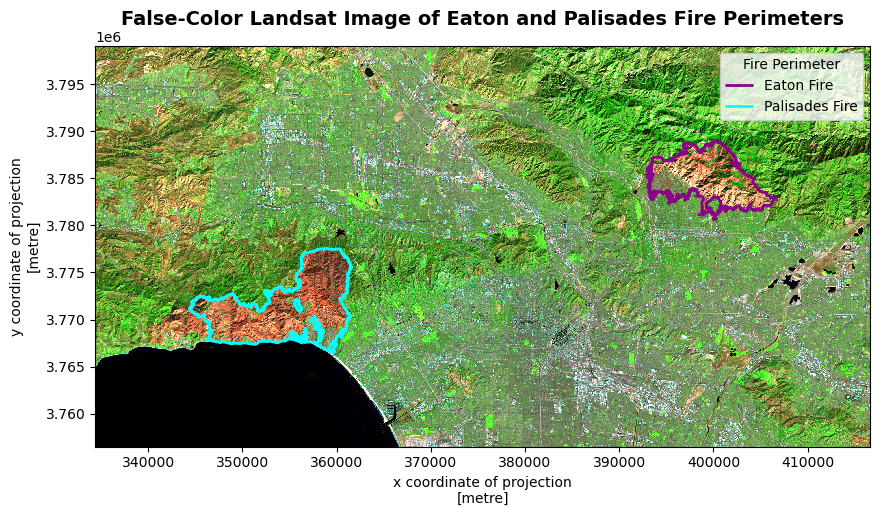

In [154]:
#A2.Create a map with shortwave infrared/near-infrared/red & fire perimeters

#Plot
#(swir22) appears as red,(nir08) as green,and (red) as blue
fig, ax=plt.subplots(figsize=(10,8))
netcdf[['swir22',"nir08","red"]].to_dataarray().plot.imshow(
    rgb="variable",
    robust=True,
    ax=ax
)
#overlays each fire perimeters as colored outlines
eaton_projected.boundary.plot(
    ax=ax,
    color='darkmagenta',
    linewidth=2,
    label="Eaton Fire"
)
palisades_projected.boundary.plot(
    ax=ax,
    color='aqua',
    linewidth=2,
    label="Palisades Fire"
)
#adding the map title and a legend
ax.set_title("False-Color Landsat Image of Eaton and Palisades Fire Perimeters",
            fontsize=14, weight='bold', pad=15)
ax.legend(title="Fire Perimeter")


plt.show()

### Summary
---
This false-color Landsat 8 image from February 23, 2025, displays the Eaton and Palisades fire perimeters. The SWIR band appears in red, near-infrared in green, and red in blue. This combination distinguishes burned areas and vegetation from the surrounding landscape. The Eaton perimeter is outlined in dark magenta, and the Palisades perimeter in aqua.

### Note:
The rest of the sections are about updating and cleaning your notebooks and repository. This is hugely important! By maintaining clean, well-structured repositories and notebooks, you’re not only showcasing your technical skills but also building a portfolio that reflects your professionalism, attention to detail, and ability to collaborate effectively with others.

Here is an example of an organized repository and notebook based on the oil spills task from homework 3.

## Clean your notebooks
---
The target audience for your notebooks is a fellow EDS 220 student who is just learning about wrangling raster data using Python.
- Add enough and appropriate comments to explain your code.
- Add enough and appropriate markdown cells to explain the procedures you are using and their output.
- The first cell in the notebook must be a markdown cell including:
- [ ] Title
- [ ] Author
- [ ] Link to GitHub repository containing the notebook (for grading purposes)

Each notebook must include an “About” section with the following subsections:
- [ ] Purpose: what is this notebook about?
- [ ] Highlights: List of highlights of analysis (3 or 4 highlights). What do you consider to be the most
- [ ] important aspects of this coding exercise?
- [ ] About the data: Datasets description
- [ ] References: Formal references to datasets. You can use the APA style as outlined here.

The rest of your notebook should be organized into logical subsections (indicated through markdown headers) for the analysis and visualization you are performing. The subsections should easily guide the reader through the analysis.

## Update your Repository
- [ ] `Title` Short, but descriptive title.
- [ ] `“About” section` A brief explanation of the repository’s purpose. Paragraphs or a bulleted list are both acceptable options. You may include an image or logo that represents the project.
- [ ] `“Repository Structure” section` A concise description of what’s housed in the repository. This includes information about the repository structure or file organization.
- [ ] `“Data” section` Details regarding data access. Any necessary information on where data lives (e.g. is it housed in the repo, on a server, in a library / package etc.) and how to access it in order to run the code.
- [ ] `“References” section`In an appropriate, consistent format, including links, provide a reference to the course and any other sources that supported the development of the repository. Include formal references to the datasets. You can use the APA style to cite data sources as outlined here.

##